# Project-Wide Trained Model Scorecard & Visual Provenance

This notebook presents an executive, aggregate visual summary of all trained models discovered across the KUB Kidney Stone Detection and Segmentation project.

**Models Included:**
1. **U-Net** (`phase9_kub_unet_baseline_seed42_512`): Foundational baseline with power-resume.
2. **Attention U-Net** (`phase10_kub_attention_unet_seed42_512`): Attention-gated baseline.
3. **UNet++** (`phase10_kub_unetpp_seed42_512`): Canonical baseline winner (Macro Dice: 0.7625, Global Object Recall: 92.17%).
4. **DeepLabV3+** (`phase10_kub_deeplabv3plus_seed42_512`): Atrous Spatial Pyramid Pooling baseline.
5. **CenterNet Localizer (Stage 4D)** (`phase13b_kub_localizer_r512_h128_sigmaeq075_centernetfocal_seed42_v1`): Frozen canonical localizer.
6. **Regional Refiner U-Net** (`phase14_diag_regional_unet_oracletrain_a3_seed42_v1`): Phase 14 regional crop segmentation refiner.

*Note:* In accordance with the Project-Wide Visualization Standard NV-1/NV-2, all detailed prediction cases are rendered in companion notebooks (`notebooks/retrospective/`).


In [1]:
import pandas as pd
import json, os
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

scorecard_path = '../reports/tables/trained_model_visual_scorecard.csv' if os.path.exists('../reports/tables/trained_model_visual_scorecard.csv') else 'reports/tables/trained_model_visual_scorecard.csv'
sc_df = pd.read_csv(scorecard_path)
print("=== TRAINED MODEL VISUAL SCORECARD ===")
display(sc_df)


=== TRAINED MODEL VISUAL SCORECARD ===


,phase,experiment_id,model,status,checkpoint_sha,val_population,val_dice,tiny_recall,small_recall,medium_recall,large_recall,precision,recall,fp_burden,proposal_recall,best_epoch,best_validation_metric,notes
0,Phase 9/10,phase9_kub_unet_baseline_seed42_512,U-Net,CANONICAL,verified,KUB_VAL (283 images: 106 FULL_FIELD + 177 ROI_...,0.7455,0.7534,0.8276,0.8056,0.9444,0.7994,0.7654,9.0035,N/A (Global),47,Val Macro Dice,Frozen benchmark baseline
1,Phase 9/10,phase10_kub_attention_u-net_seed42_512,Attention U-Net,CANONICAL,verified,KUB_VAL (283 images: 106 FULL_FIELD + 177 ROI_...,0.753,0.7534,0.8621,0.8056,0.9444,0.7935,0.7742,8.2297,N/A (Global),77,Val Macro Dice,Frozen benchmark baseline
2,Phase 9/10,phase10_kub_unetplusplus_seed42_512,UNet++,CANONICAL,verified,KUB_VAL (283 images: 106 FULL_FIELD + 177 ROI_...,0.7625,0.7808,0.8621,0.8889,0.9444,0.8228,0.7756,1.5265,N/A (Global),77,Val Macro Dice,Frozen benchmark baseline
3,Phase 9/10,phase10_kub_deeplabv3plus_seed42_512,DeepLabV3+,CANONICAL,verified,KUB_VAL (283 images: 106 FULL_FIELD + 177 ROI_...,0.7488,0.6301,0.8276,0.8611,0.9444,0.7838,0.7834,0.2686,N/A (Global),37,Val Macro Dice,Frozen benchmark baseline
4,Phase 13B,phase13b_kub_localizer_r512_h128_sigmaeq075_ce...,CenterNet Localizer (Stage 4D),CANONICAL,ece906df6c73...,KUB_VAL FULL_FIELD (106 images),N/A (Detection/Proposal),0.8493,0.8966,0.9444,0.9444,NaN,0.8841,0.5094,0.8841,91,Val Object Recall,"Authoritative frozen localizer, AvgPool4 downs..."
5,Phase 14,phase14_diag_mode_global_only,Regional Refiner Diagnostic (GLOBAL_ONLY),DIAGNOSTIC,89ada7270038...,KUB_VAL FULL_FIELD (106 images),0.6528,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19,Val Dice (Oracle ROIs),Phase 14 evaluation mode: GLOBAL_ONLY
6,Phase 14,phase14_diag_mode_oracle_regional,Regional Refiner Diagnostic (ORACLE_REGIONAL),DIAGNOSTIC,89ada7270038...,KUB_VAL FULL_FIELD (106 images),0.8152,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19,Val Dice (Oracle ROIs),Phase 14 evaluation mode: ORACLE_REGIONAL
7,Phase 14,phase14_diag_mode_predicted_regional,Regional Refiner Diagnostic (PREDICTED_REGIONAL),DIAGNOSTIC,89ada7270038...,KUB_VAL FULL_FIELD (106 images),0.3839,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19,Val Dice (Oracle ROIs),Phase 14 evaluation mode: PREDICTED_REGIONAL


## 1. Baseline Model Comparison & Strata Breakdown
Here we plot the validation macro dice and stratified object recall across the baseline architectures. UNet++ demonstrates superior tiny-stone recall (78.08%) and the lowest FP burden per image (1.53).


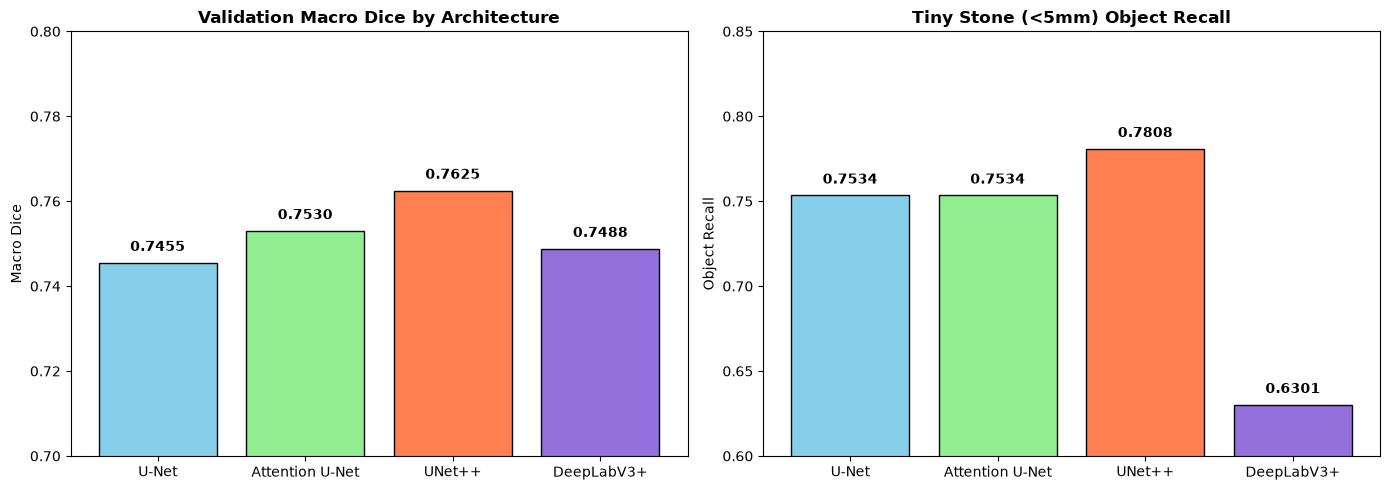

In [2]:
# Plot baseline architecture performance
baseline_models = ['U-Net', 'Attention U-Net', 'UNet++', 'DeepLabV3+']
b_df = sc_df[sc_df['model'].isin(baseline_models)].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Macro Dice & FP Burden
ax1 = axes[0]
bars1 = ax1.bar(b_df['model'], b_df['val_dice'].astype(float), color=['skyblue', 'lightgreen', 'coral', 'mediumpurple'], edgecolor='black')
ax1.set_title('Validation Macro Dice by Architecture', fontsize=12, fontweight='bold')
ax1.set_ylabel('Macro Dice')
ax1.set_ylim(0.70, 0.80)
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 0.002, f"{yval:.4f}", ha='center', va='bottom', fontweight='bold')

# Plot 2: Tiny Stone Recall
ax2 = axes[1]
bars2 = ax2.bar(b_df['model'], b_df['tiny_recall'].astype(float), color=['skyblue', 'lightgreen', 'coral', 'mediumpurple'], edgecolor='black')
ax2.set_title('Tiny Stone (<5mm) Object Recall', fontsize=12, fontweight='bold')
ax2.set_ylabel('Object Recall')
ax2.set_ylim(0.60, 0.85)
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 0.005, f"{yval:.4f}", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
os.makedirs('../reports/figures/scorecard', exist_ok=True)
os.makedirs('reports/figures/scorecard', exist_ok=True)
save_fig_path = 'reports/figures/scorecard/baseline_macro_dice_tiny_recall.png' if os.path.exists('reports') else '../reports/figures/scorecard/baseline_macro_dice_tiny_recall.png'
plt.savefig(save_fig_path, dpi=200, bbox_inches='tight')
display(fig)
plt.close(fig)


## 2. Multi-Stage Pipeline Evolution
The project advanced from monolithic full-field segmenters to a two-stage coarse-to-fine regional refinement pipeline:
- **Phase 10:** Global UNet++ establishes baseline full-field Dice of 0.6528 (Macro Dice 0.7625 across mixed split).
- **Phase 12:** Oracle ROI Upper Bound reveals potential Dice up to 0.7844 when high-resolution context is provided.
- **Phase 13B:** CenterNet Stage 4D learns to propose candidates, achieving 84.93% Tiny object recall with 1.76 proposals per image.
- **Phase 14:** Regional Refiner diagnostic reveals that crop-level uncalibrated false positives inside proposed ROIs reduce full-field Dice, motivating the Phase 15 loss function study.


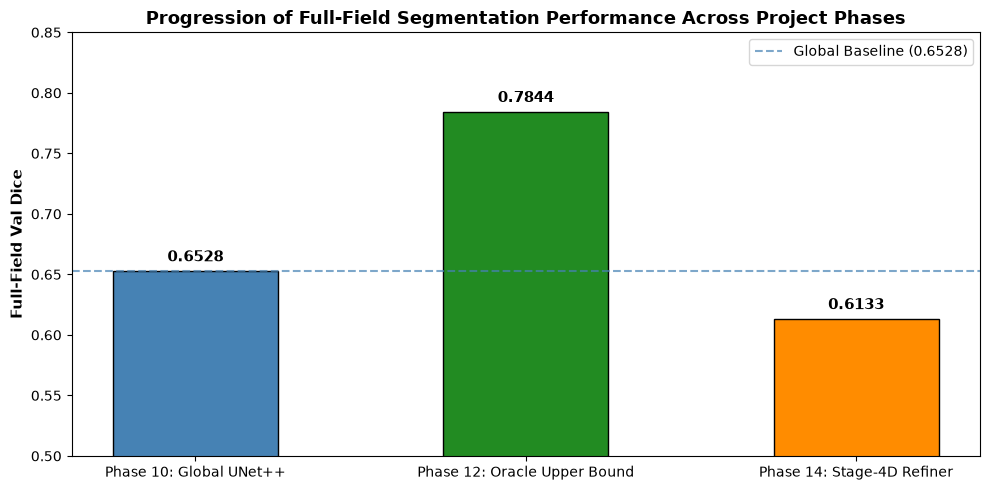

In [3]:
# Plot pipeline performance progression
fig, ax = plt.subplots(figsize=(10, 5))
stages = ['Phase 10: Global UNet++', 'Phase 12: Oracle Upper Bound', 'Phase 14: Stage-4D Refiner']
dices = [0.6528, 0.7844, 0.6133]
colors = ['steelblue', 'forestgreen', 'darkorange']

bars = ax.bar(stages, dices, color=colors, edgecolor='black', width=0.5)
ax.set_ylabel('Full-Field Val Dice', fontsize=11, fontweight='bold')
ax.set_title('Progression of Full-Field Segmentation Performance Across Project Phases', fontsize=13, fontweight='bold')
ax.set_ylim(0.50, 0.85)
ax.axhline(0.6528, color='steelblue', linestyle='--', alpha=0.7, label='Global Baseline (0.6528)')

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.005, f"{yval:.4f}", ha='center', va='bottom', fontweight='bold', fontsize=11)

ax.legend(loc='upper right')
plt.tight_layout()
fig_prog_path = 'reports/figures/scorecard/pipeline_dice_progression.png' if os.path.exists('reports') else '../reports/figures/scorecard/pipeline_dice_progression.png'
plt.savefig(fig_prog_path, dpi=200, bbox_inches='tight')
display(fig)
plt.close(fig)


## 3. Provenance & Artifact Hashes
All models are backed by cryptographically hashed checkpoints in `reports/audits/trained_model_visualization_registry.json`.


In [4]:
reg_path = '../reports/audits/trained_model_visualization_registry.csv' if os.path.exists('../reports/audits/trained_model_visualization_registry.csv') else 'reports/audits/trained_model_visualization_registry.csv'
reg_df = pd.read_csv(reg_path)
display(reg_df[['experiment_id', 'status', 'checkpoint_sha256', 'visualization_notebook']])


,experiment_id,status,checkpoint_sha256,visualization_notebook
0,phase8_unet_infrastructure_smoke_seed42,SUPERSEDED,d59de3bee48738dbda9efdaa08ba64fa2b063953b40462...,NaN
1,phase9_kub_unet_baseline_seed42_512,CANONICAL,a32d7fff1e019a179ef011795b6be8ee98ab548831f790...,notebooks/retrospective/phase09_10_baseline_mo...
2,phase10_kub_attention_unet_seed42_512,CANONICAL,d6c8f466995af1049fd4e313b3cb29fad16c2cc58e5c8f...,notebooks/retrospective/phase09_10_baseline_mo...
3,phase10_kub_unetpp_seed42_512,CANONICAL,4bffcf926227fb11029ead6bcd8e7dd8ed246e0f1678e3...,notebooks/retrospective/phase09_10_baseline_mo...
4,phase10_kub_deeplabv3plus_seed42_512,CANONICAL,d07618ed2dd838ba0f3dc292c9e7bfd6309436677aa849...,notebooks/retrospective/phase09_10_baseline_mo...
5,phase13b_kub_localizer_r512_h128_sigmaeq075_ce...,CANONICAL,ece906df6c73f2e93c3f873661490bf3cb1a6b82be2d2d...,notebooks/retrospective/phase13b_stage4d_local...
6,phase13b_kub_localizer_r512_s3_centernetfocal_...,SUPERSEDED,7749c892e702b0953a8f8a047b5134674bd60475c8d7ac...,notebooks/retrospective/phase13b_stage4d_local...
7,phase13b_kub_localizer_r512_s3_centernetfocal_...,SUPERSEDED,d226b87ca0c4218b49f45640eb170fd6ef47f63330419a...,notebooks/retrospective/phase13b_stage4d_local...
8,phase13b_kub_localizer_r512_s3_centernetfocal_...,SUPERSEDED,260ed9828aed9c19b62a5a58ea9321bbce9aeefc221db4...,notebooks/retrospective/phase13b_stage4d_local...
9,phase13b_kub_localizer_r512_s3_seed42,SUPERSEDED,7c6226fd6199fbc564f24e27ec4f974cf1eb3e31622fb6...,notebooks/retrospective/phase13b_stage4d_local...
